# AI-assisted tree DBH measurement — MobileSAMv2 depth-guided pipeline (minimal reproduction)

Paper: **"Artificial intelligence-assisted tree diameter-at-breast-height measurement"** (IOP *Measurement Science and Technology*, DOI [10.1088/1361-6501/aebfb9](https://doi.org/10.1088/1361-6501/aebfb9)).
Author code: `yinzhiheng/AI-assisted-DBH-measurement-pipeline` @ commit `672e7543123741ad11f2b41fdaeaec313427b555`.

**Executed scope (partial demonstration, CPU):** the paper's **MobileSAMv2 depth-guided framework** end-to-end — LiDAR depth + RGB from an iPhone 15 Pro, depth-guided box prompt, MobileSAMv2 ONNX segmentation (authors' exported opset-16 models), geometric DBH from the authors' C++ pipeline — on the **first `MAX_FILES` sorted images per dataset** (plotted + natural), compared against caliper reference DBH. SAM3.1 (text-prompt) is **out of scope** here: its checkpoint is a multi-GB Dropbox share and its paper-timed path is GPU-bound (3.71 s/image on T4); this notebook reproduces the deployment-ready MobileSAMv2 route (~0.89 s/image on iPhone, CPU-native).

**AI-assisted adaptation notice (EN):** the scientific C++ sources are the authors' own, compiled verbatim on Linux with five small, documented compatibility patches (entry point, `windows.h` guards, wide-string option parser, package-root lookup, one out-of-line constructor for GCC). No algorithm was changed. The authors did not provide this Linux/Colab build; the executed example and checks below were validated, but untested behavior is not guaranteed.

**AI-adapted notice (JA):** 本ノートブックは著者提供のC++ソースをLinux用に最小限の互換パッチ(4箇所、アルゴリズム不変)でColab上でビルド・実行するものです。SAM3.1経路は対象外。実行例は検証済みですが、未検証の挙動は保証されません。

Dataset: 202 planted (black walnut, John Wright Forestry Center) and 285 natural-forest (Martell Forest) trees, iPhone 15 Pro RGB (1920×1440) + LiDAR depth (256×192), caliper reference (Haglöf Mantax Blue, 0.1 cm). This notebook is a **small-sample plausibility demonstration, not a reproduction of the paper's dataset-level accuracy (RMSE 1.0 cm planted / 1.9 cm natural for MobileSAMv2)**.

## Runtime selection / ランタイム選択

**Use a CPU runtime** (Runtime → Change runtime type → CPU). The MobileSAMv2 C++ pipeline is a CPU workload by design — the paper reports ~0.89 s/image on an iPhone, and the C++ ONNX Runtime path uses the CPU execution provider. No CUDA code exists in this path; a GPU adds nothing scientifically here.

**Run all** (Runtime → Run all). Expected: a few minutes total; downloads ≈ 200 MB (OpenCV dev packages, ONNX Runtime 1.24.1, two ONNX models, a few RGB/depth samples).

** JA:** **CPUランタイム**を使用してください。MobileSAMv2経路はCPU設計(iPhoneで約0.89秒/枚)。GPUは本経路に不要です。Run allで数分、ダウンロード約200MBです。

**Not executed here / 本例で再現しないもの:** SAM3.1 framework, the full 202/285-tree benchmarks, iPhone on-device timing, and the authors' full visualization notebook (`visualization/fusedSAM_visualization_clean.ipynb`).

### 3.1 System dependencies

Install the C++ toolchain and OpenCV development headers (the paper's pipeline links OpenCV 4.x; the Colab image provides `libopencv-dev` from Ubuntu). This cell prints the installed versions as evidence.

** JA:** C++ツールチェーンとOpenCV開発ヘッダをインストールし、バージョンを表示します。

In [ ]:
import subprocess, sys, shutil

def run(cmd, **kw):
    print('$', ' '.join(cmd), flush=True)
    return subprocess.run(cmd, check=True, **kw)

run(['apt-get', '-qq', 'update'])
run(['apt-get', '-qq', 'install', '-y', 'libopencv-dev', 'g++', 'pkg-config'])

print(shutil.which('g++'))
print(run(['g++', '--version'], capture_output=True, text=True).stdout.splitlines()[0])
print(run(['pkg-config', '--modversion', 'opencv4'], capture_output=True, text=True).stdout.strip())

$ apt-get -qq update


$ apt-get -qq install -y libopencv-dev g++ pkg-config


/usr/bin/g++
$ g++ --version


g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
$ pkg-config --modversion opencv4


4.6.0


### 3.2 ONNX Runtime (C++)

The authors' pipeline uses **ONNX Runtime 1.24.1** (paper §implementation: C++, OpenCV 4.11, ONNX Runtime 1.24.1, opset 16). We download the official prebuilt Linux x64 CPU package from the Microsoft release (version matching the paper) and record its provenance.

** JA:** 論文と同じONNX Runtime 1.24.1(CPU版、公式プレビルド)を取得します。

In [ ]:
import urllib.request, pathlib, tarfile

ORT_VERSION = '1.24.1'
ORT_TGZ = f'onnxruntime-linux-x64-{ORT_VERSION}.tgz'
ORT_URL = f'https://github.com/microsoft/onnxruntime/releases/download/v{ORT_VERSION}/{ORT_TGZ}'

ort_dir = pathlib.Path('/content/deps')
ort_dir.mkdir(parents=True, exist_ok=True)
tgz = ort_dir / ORT_TGZ
if not tgz.exists():
    print('downloading', ORT_URL, flush=True)
    urllib.request.urlretrieve(ORT_URL, tgz)
print('downloaded bytes:', tgz.stat().st_size)

with tarfile.open(tgz) as tf:
    tf.extractall(ort_dir)
ORT_ROOT = ort_dir / f'onnxruntime-linux-x64-{ORT_VERSION}'
assert (ORT_ROOT / 'lib' / 'libonnxruntime.so').is_file()
assert (ORT_ROOT / 'include' / 'onnxruntime_cxx_api.h').is_file()
print('ORT_ROOT =', ORT_ROOT)

downloading https://github.com/microsoft/onnxruntime/releases/download/v1.24.1/onnxruntime-linux-x64-1.24.1.tgz


downloaded bytes: 8115952


/tmp/ipykernel_2584/4270341785.py:16: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf.extractall(ort_dir)


ORT_ROOT = /content/deps/onnxruntime-linux-x64-1.24.1


### 4. Author source retrieval (pinned commit)

Fetch **only** the C++ files needed for the MobileSAMv2 route plus the two ONNX models and the four label/base-point CSVs, from the pinned commit via `raw.githubusercontent.com`. Every file is verified against its **git blob SHA-1 and byte size** recorded from the pinned repository tree (git blob hash = SHA-1 of `blob <len>\\0` + content). Nothing outside this allowlist is downloaded.

** JA:** MobileSAMv2経路に必要なC++ソース・ONNXモデル・CSVのみ、ピン留めコミットから取得し、各ファイルのgit blob SHA-1とサイズを検証します。

In [ ]:
import hashlib, urllib.request, pathlib

REPO = 'yinzhiheng/AI-assisted-DBH-measurement-pipeline'
COMMIT = '672e7543123741ad11f2b41fdaeaec313427b555'
RAW = f'https://raw.githubusercontent.com/{REPO}/{COMMIT}/'
PROJECT = pathlib.Path('/content/dbh_project')

# path -> (expected bytes, git blob sha1)  from the pinned tree (verified 2026-11-14)
PINNED = {
    'codes/DBH/DBHCalculationBatch.sln': (1792, '1327b63ecc57317c29eac7079de37a2920b2e64c'),
    'codes/DBH/batchProcessing/batchProcessPlotDatasetByMobileSAMv2.cpp': (12858, '0b1cc59fa808c4997f5c184fdb4b32e3f6d3fa41'),
    'codes/DBH/batchProcessing/batchProcessNaturalDatasetByMobileSAMv2.cpp': (14096, '65a1a06bcad4e9eac4b3bea42dfb03c4480dba54'),
    'codes/DBH/src/BatchProcessing/BatchInput.cpp': (2735, '5322ddbc834f477cc0a844567dc9e303df7e15f8'),
    'codes/DBH/src/BatchProcessing/BatchInput.h': (588, '9516d00316cdd6db150885454fe25bdbef5e7499'),
    'codes/DBH/src/BatchProcessing/BatchPaths.h': (2242, '9f10acd3f59910938f6890dfd376f259494712de'),
    'codes/DBH/src/BatchProcessing/MobileSAMBatchDebug.h': (5044, 'b20bd6e8e48f203150e51876f767cf3ebb050d71'),
    'codes/DBH/src/BreastHeightLocalizer/BreastHeightLocalizer.cpp': (27088, 'e3597434543e7104790b4e6869f395cf919349a3'),
    'codes/DBH/src/BreastHeightLocalizer/BreastHeightLocalizer.h': (4148, '904b543524cad013ab4f2e07da070599699123ab'),
    'codes/DBH/src/CameraModel/CameraModel.cpp': (1788, 'c592cf0cefcdb290f5e7df63f2ca15a2b7dbebeb'),
    'codes/DBH/src/CameraModel/CameraModel.h': (1041, 'd0276881166e40258d3ff8917ecc521367295ea9'),
    'codes/DBH/src/DBHMeasurer/DBHMeasurer.cpp': (97821, 'e86c07cef2615fe98970685e35af0d2d29b49688'),
    'codes/DBH/src/DBHMeasurer/DBHMeasurer.h': (8445, '53a603414499982ed7ce04a86e7abdaee66f1b68'),
    'codes/DBH/src/DBHMeasurer/SAM3DebugVisualization.h': (2697, 'edcb87d885b3b6ef90c3503d866ec57707d26f9a'),
    'codes/DBH/src/DepthFrame/DepthFrame.cpp': (1755, 'f1c6a7f436d9d9486c20150745408abc46a59320'),
    'codes/DBH/src/DepthFrame/DepthFrame.h': (2005, 'be7ac97e80e1b6d3035577fe63f482e6053aaadd'),
    'codes/DBH/src/Load/load.cpp': (11214, '8db9fcb1fec0449a583765fd426c3450161dfb4a'),
    'codes/DBH/src/Load/load.h': (1834, '5e438c1f3e043268bfadbf37d3c76b2921dd1fb1'),
    'codes/DBH/src/SegmentationModel/sam.cpp': (25929, 'd0fc7986d8136d95d0e8c322fd197cd437030fec'),
    'codes/DBH/src/SegmentationModel/sam.hpp': (2202, '2352172d541519008e83f81aafe8b2f79e3b4f76'),
    'codes/DBH/src/SegmentationModel/TreeMask.h': (2298, '6ae54a775d3a5bd77bfca3b350a0da6f47af3982'),
    'codes/DBH/src/configs/configs.cpp': (105, 'ab6e4abb1c87c8b83d145c03f11d0c8abc017100'),
    'codes/DBH/src/configs/configs.h': (1477, 'f5eec8b89568d7c3cbc2beb1fe7f02754e9ae9c4'),
    'model/MobileSAMv2/onnx/mobile_sam_preprocess.onnx': (28194128, 'b3b0c580a1754e8564c77c6a8d01a682debc34a5'),
    'model/MobileSAMv2/onnx/mobile_sam.onnx': (16511562, 'e60e0cb80d243a0f4ae7d4fddfe40dc853064a0a'),
    'data/basePoints_plotted.csv': (12007, '735abd7bbe225fddd18029d37ebbde4c9ab4c23e'),
    'data/basePoints_natural.csv': (22275, '0538dd2786e478c6d479288b474c72a4c4dff5b0'),
    'data/labelsForPlottedField.csv': (14641, '65c98b34c53bc8ae02c943fc3c0d89c607b38c0e'),
    'data/labelsForNaturalField.csv': (23667, '3a4bd033d6b602275444c1b938bdf8f4ff4683ba'),
}

def blob_sha1(data: bytes) -> str:
    return hashlib.sha1(b'blob %d\x00' % len(data) + data).hexdigest()

def fetch(rel_path: str) -> bytes:
    url = RAW + rel_path
    with urllib.request.urlopen(url, timeout=120) as r:
        data = r.read()
    expected_size, expected_sha = PINNED[rel_path]
    assert len(data) == expected_size, f'{rel_path}: size {len(data)} != {expected_size}'
    assert blob_sha1(data) == expected_sha, f'{rel_path}: blob sha1 mismatch'
    return data

for rel in PINNED:
    dest = PROJECT / rel
    dest.parent.mkdir(parents=True, exist_ok=True)
    dest.write_bytes(fetch(rel))
    print('OK', rel, PINNED[rel][0], 'bytes')
print('project tree ready at', PROJECT)

OK codes/DBH/DBHCalculationBatch.sln 1792 bytes
OK codes/DBH/batchProcessing/batchProcessPlotDatasetByMobileSAMv2.cpp 12858 bytes


OK codes/DBH/batchProcessing/batchProcessNaturalDatasetByMobileSAMv2.cpp 14096 bytes
OK codes/DBH/src/BatchProcessing/BatchInput.cpp 2735 bytes


OK codes/DBH/src/BatchProcessing/BatchInput.h 588 bytes
OK codes/DBH/src/BatchProcessing/BatchPaths.h 2242 bytes
OK codes/DBH/src/BatchProcessing/MobileSAMBatchDebug.h 5044 bytes


OK codes/DBH/src/BreastHeightLocalizer/BreastHeightLocalizer.cpp 27088 bytes
OK codes/DBH/src/BreastHeightLocalizer/BreastHeightLocalizer.h 4148 bytes


OK codes/DBH/src/CameraModel/CameraModel.cpp 1788 bytes
OK codes/DBH/src/CameraModel/CameraModel.h 1041 bytes


OK codes/DBH/src/DBHMeasurer/DBHMeasurer.cpp 97821 bytes
OK codes/DBH/src/DBHMeasurer/DBHMeasurer.h 8445 bytes
OK codes/DBH/src/DBHMeasurer/SAM3DebugVisualization.h 2697 bytes


... (3 outputs left out)

OK codes/DBH/src/configs/configs.h 1477 bytes


OK model/MobileSAMv2/onnx/mobile_sam_preprocess.onnx 28194128 bytes


OK model/MobileSAMv2/onnx/mobile_sam.onnx 16511562 bytes
OK data/basePoints_plotted.csv 12007 bytes
OK data/basePoints_natural.csv 22275 bytes


OK data/labelsForPlottedField.csv 14641 bytes
OK data/labelsForNaturalField.csv 23667 bytes
project tree ready at /content/dbh_project


### 5. Minimal sample selection (first `MAX_FILES` sorted images per dataset)

The batch programs process depth files whose names start with `combine-`, **sorted by filename**, optionally truncated to the first `max_files`. We replicate that deterministic selection: one call to the public GitHub **tree API** at the pinned commit (truncation is rejected), then the first `MAX_FILES` depth PNGs and their paired RGB JPEGs per dataset are fetched from pinned raw URLs and blob-hash verified. `MAX_FILES = 2` keeps the demo small; raise it (or set `0` for all 202/285) to widen the example.

** JA:** バッチプログラムと同じ「ファイル名ソート先頭MAX_FILES枚」の決定的選択を再現します。GitHubツリーAPIでファイル一覧を取得し(切り詰めは拒否)、RGB/深度ペアをblobハッシュ検証付きで取得します。

In [ ]:
import json, urllib.request

MAX_FILES = 2  # first N sorted depth images per dataset; 0 = all (202 plotted / 285 natural)

TREE_URL = f'https://api.github.com/repos/{REPO}/git/trees/{COMMIT}?recursive=1'
req = urllib.request.Request(TREE_URL, headers={'User-Agent': 'colab-dbh-reproduction'})
with urllib.request.urlopen(req, timeout=120) as r:
    tree = json.load(r)
assert not tree.get('truncated'), 'GitHub tree listing was truncated; refusing to guess'
entries = {e['path']: e for e in tree['tree'] if e['type'] == 'blob'}
print('tree entries:', len(entries))

def dataset_files(subdir: str, prefix: str, ext: str):
    names = sorted(p for p in entries if p.startswith(f'data/rawdata/{subdir}/') and p.endswith(ext))
    selected = names if MAX_FILES == 0 else names[:MAX_FILES]
    return selected

def fetch_verified(rel_path: str) -> bytes:
    e = entries[rel_path]
    with urllib.request.urlopen(RAW + rel_path, timeout=180) as r:
        data = r.read()
    assert len(data) == e['size'], f'{rel_path}: size {len(data)} != {e["size"]}'
    assert blob_sha1(data) == e['sha'], f'{rel_path}: blob sha1 mismatch'
    return data

samples = {}
for name, depth_sub, rgb_sub in [('plotted', 'depth_plottedField', 'rgb_plottedField'),
                                 ('natural', 'depth_naturalField', 'rgb_naturalField')]:
    depth_files = dataset_files(depth_sub, 'combine-', '.png')
    assert depth_files, f'no combine-*.png under {depth_sub}'
    samples[name] = []
    for dep in depth_files:
        dep_data = fetch_verified(dep)
        (PROJECT / dep).parent.mkdir(parents=True, exist_ok=True)
        (PROJECT / dep).write_bytes(dep_data)
        stem = pathlib.Path(dep).stem[len('combine-'):]
        rgb_rel = f'data/rawdata/{rgb_sub}/rgb-{stem}.jpeg'
        rgb_data = fetch_verified(rgb_rel)
        (PROJECT / rgb_rel).parent.mkdir(parents=True, exist_ok=True)
        (PROJECT / rgb_rel).write_bytes(rgb_data)
        samples[name].append(stem)
        print('sample', name, stem, len(dep_data), '+', len(rgb_data), 'bytes')
print(json.dumps({k: len(v) for k, v in samples.items()}), 'samples per dataset')

tree entries: 3821


sample plotted 015F8CF6-A9A6-4C8F-B7F2-93904FB04611-240821162430 34456 + 1919330 bytes


sample plotted 035A58BF-8751-422E-9AB5-49E6FF51D266-240821153726 32048 + 1598135 bytes


sample natural 00CE6EF7-1B18-4126-BDE8-80855AC4656C-240502114743 63201 + 1654702 bytes


sample natural 01B59F0F-19A1-4514-987F-81C3E69CC69E-240502122621 42904 + 1686189 bytes
{"plotted": 2, "natural": 2} samples per dataset


### 6. Documented Linux compatibility patches (glue only, no algorithm changes)

Five mechanical patches adapt the Windows/MSVC-only glue; all algorithm code stays verbatim:
1. `batchProcess*.cpp`: `wmain(wchar_t*)` → `main(char*)` (Linux entry point).
2. `BatchInput.cpp`: drop `#include <windows.h>` (it only sets `NOMINMAX` there).
3. `MobileSAMBatchDebug.h`: wide-string (`wchar_t`) option parser → narrow strings (the exporter's PNG writing is unchanged).
4. `BatchPaths.h`: replace the Windows-only `GetModuleFileNameW` executable lookup with a current-directory walk-up; the same package-root validation (`codes/DBH/DBHCalculationBatch.sln` + `codes/DBH/src`) is preserved. All runs below pass the explicit project root anyway.
5. `BreastHeightLocalizer`: define the zero-argument constructor out-of-line — GCC (unlike MSVC) requires a nested class's default member initializers to be complete before a `Params()` default argument inside the enclosing class (CWG 1397). Identical construction behavior.

Each replacement asserts the original author text matched exactly, so a changed upstream file fails loudly.

** JA:** Windows専用のグルーコード4箇所のみを機械的に置換します(アルゴリズム不変)。各置換は元テキストの完全一致を要求し、上游変更時は失敗します。

In [ ]:
import re

def patch(path: str, old: str, new: str):
    p = PROJECT / path
    # surrogateescape round-trips non-UTF-8 bytes (some author files are Latin-1).
    text = p.read_text(encoding='utf-8', errors='surrogateescape')
    assert text.count(old) == 1, f'{path}: expected exactly one occurrence of patch target'
    p.write_text(text.replace(old, new), encoding='utf-8', errors='surrogateescape')
    print('patched', path)

patch('codes/DBH/batchProcessing/batchProcessPlotDatasetByMobileSAMv2.cpp',
      'int wmain(int argc, wchar_t* argv[])', 'int main(int argc, char* argv[])')
patch('codes/DBH/batchProcessing/batchProcessNaturalDatasetByMobileSAMv2.cpp',
      'int wmain(int argc, wchar_t* argv[])', 'int main(int argc, char* argv[])')

patch('codes/DBH/src/BatchProcessing/BatchInput.cpp',
      '#ifndef NOMINMAX\n#define NOMINMAX\n#endif\n#include <windows.h>\n',
      '#define NOMINMAX 1\n')

patch('codes/DBH/src/BatchProcessing/MobileSAMBatchDebug.h',
      '    std::vector<std::wstring> positional;', '    std::vector<std::string> positional;')
patch('codes/DBH/src/BatchProcessing/MobileSAMBatchDebug.h',
      'inline MobileSAMBatchOptions ParseMobileSAMBatchOptions(int argc, wchar_t* argv[])',
      'inline MobileSAMBatchOptions ParseMobileSAMBatchOptions(int argc, char* argv[])')
patch('codes/DBH/src/BatchProcessing/MobileSAMBatchDebug.h',
      '    options.positional.emplace_back(argv[0]);', '    options.positional.emplace_back(argv[0]);')
patch('codes/DBH/src/BatchProcessing/MobileSAMBatchDebug.h',
      '        const std::wstring argument(argv[i]);', '        const std::string argument(argv[i]);')
patch('codes/DBH/src/BatchProcessing/MobileSAMBatchDebug.h',
      '        if (argument == L"--save-masks") options.saveMasks = true;\n        else if (argument == L"--help") options.help = true;\n        else if (argument == L"--debug-dir") {\n            if (++i >= argc || std::wstring(argv[i]).rfind(L"--", 0) == 0)',
      '        if (argument == "--save-masks") options.saveMasks = true;\n        else if (argument == "--help") options.help = true;\n        else if (argument == "--debug-dir") {\n            if (++i >= argc || std::string(argv[i]).rfind("--", 0) == 0)')
patch('codes/DBH/src/BatchProcessing/MobileSAMBatchDebug.h',
      '        else if (argument.rfind(L"--", 0) == 0)', '        else if (argument.rfind("--", 0) == 0)')

patch('codes/DBH/src/BatchProcessing/BatchPaths.h',
      '#ifndef NOMINMAX\n#define NOMINMAX\n#endif\n#ifndef WIN32_LEAN_AND_MEAN\n#define WIN32_LEAN_AND_MEAN\n#endif\n#include <windows.h>\n',
      '#define NOMINMAX 1\n')
patch('codes/DBH/src/BatchProcessing/BatchPaths.h',
      '''        std::vector<wchar_t> buffer(1024);
        for (;;) {
            const DWORD count = GetModuleFileNameW(nullptr, buffer.data(),
                                                   static_cast<DWORD>(buffer.size()));
            if (count == 0) throw std::runtime_error("Cannot locate the batch executable");
            if (count < buffer.size()) {
                root = fs::path(std::wstring(buffer.data(), count)).parent_path();
                break;
            }
            if (buffer.size() >= 32768)
                throw std::runtime_error("Batch executable path is too long");
            buffer.resize(buffer.size() * 2);
        }
        while (!fs::is_regular_file(root / "codes/DBH/DBHCalculationBatch.sln")) {''',
      '''        // Linux/Colab adaptation: walk up from the current directory to the
        // package root instead of GetModuleFileNameW (Windows-only API).
        root = fs::current_path();
        while (!fs::is_regular_file(root / "codes/DBH/DBHCalculationBatch.sln")) {''')

# GCC (unlike MSVC) requires a nested class's default member initializers to be
# complete before a default argument `Params()` inside the enclosing class
# (CWG 1397). Moving the zero-argument constructor out-of-line preserves the
# exact same construction behavior.
patch('codes/DBH/src/BreastHeightLocalizer/BreastHeightLocalizer.h',
      '    explicit BreastHeightLocalizer(Params p = Params()) : m_p(p) {}',
      '    BreastHeightLocalizer();\n    explicit BreastHeightLocalizer(Params p) : m_p(p) {}')
patch('codes/DBH/src/BreastHeightLocalizer/BreastHeightLocalizer.cpp',
      '#include <iostream>\n',
      '#include <iostream>\n\n// Out-of-line zero-argument constructor (Linux/GCC adaptation; see notebook \u00a76).\nBreastHeightLocalizer::BreastHeightLocalizer() : m_p(Params()) {}\n')
print('all patches applied')

patched codes/DBH/batchProcessing/batchProcessPlotDatasetByMobileSAMv2.cpp
patched codes/DBH/batchProcessing/batchProcessNaturalDatasetByMobileSAMv2.cpp
patched codes/DBH/src/BatchProcessing/BatchInput.cpp
patched codes/DBH/src/BatchProcessing/MobileSAMBatchDebug.h
patched codes/DBH/src/BatchProcessing/MobileSAMBatchDebug.h
patched codes/DBH/src/BatchProcessing/MobileSAMBatchDebug.h
patched codes/DBH/src/BatchProcessing/MobileSAMBatchDebug.h
patched codes/DBH/src/BatchProcessing/MobileSAMBatchDebug.h
patched codes/DBH/src/BatchProcessing/MobileSAMBatchDebug.h
patched codes/DBH/src/BatchProcessing/BatchPaths.h
patched codes/DBH/src/BatchProcessing/BatchPaths.h
patched codes/DBH/src/BreastHeightLocalizer/BreastHeightLocalizer.h
patched codes/DBH/src/BreastHeightLocalizer/BreastHeightLocalizer.cpp
all patches applied


### 7. Build the author's C++ pipeline

Compile the verbatim author sources (plus the patched glue) against OpenCV and ONNX Runtime. Two binaries result, exactly mirroring the repository's batch programs: `batchProcessPlotDatasetByMobileSAMv2` and `batchProcessNaturalDatasetByMobileSAMv2`.

** JA:** 著者のソースをそのまま(パッチ済みグルーコードのみ差し替えて)OpenCVとONNX Runtimeにリンクして2つのバッチ実行ファイルをビルドします。

In [ ]:
import subprocess, os

SRC = PROJECT / 'codes/DBH/src'
OPENCV_CFLAGS = subprocess.run(['pkg-config', '--cflags', 'opencv4'],
                               capture_output=True, text=True, check=True).stdout.split()
INCLUDES = [f'-I{SRC}/{d}' for d in
            ['Load', 'CameraModel', 'DepthFrame', 'BreastHeightLocalizer',
             'DBHMeasurer', 'SegmentationModel', 'configs', 'BatchProcessing']]
INCLUDES += OPENCV_CFLAGS + [f'-I{ORT_ROOT}/include']

COMMON_SRC = [
    SRC / 'Load/load.cpp',
    SRC / 'CameraModel/CameraModel.cpp',
    SRC / 'DepthFrame/DepthFrame.cpp',
    SRC / 'BreastHeightLocalizer/BreastHeightLocalizer.cpp',
    SRC / 'DBHMeasurer/DBHMeasurer.cpp',
    SRC / 'SegmentationModel/sam.cpp',
    SRC / 'configs/configs.cpp',
    SRC / 'BatchProcessing/BatchInput.cpp',
]
OPENCV_LIBS = subprocess.run(['pkg-config', '--libs', 'opencv4'],
                             capture_output=True, text=True, check=True).stdout.split()

def build(batch_cpp: str, out_name: str):
    cmd = ['g++', '-std=c++17', '-O2'] + INCLUDES + [
        str(PROJECT / 'codes/DBH/batchProcessing' / batch_cpp),
        *[str(s) for s in COMMON_SRC],
        f'-L{ORT_ROOT}/lib', f'-Wl,-rpath,{ORT_ROOT}/lib', '-lonnxruntime',
        *OPENCV_LIBS, '-o', f'/content/{out_name}']
    print(' '.join(cmd), flush=True)
    proc = subprocess.run(cmd, capture_output=True, text=True)
    if proc.returncode != 0:
        print(proc.stderr[-8000:], flush=True)
        raise RuntimeError(f'compile failed for {batch_cpp} (exit {proc.returncode})')
    print('built', out_name)

build('batchProcessPlotDatasetByMobileSAMv2.cpp', 'dbh_mobilesamv2_plot')
build('batchProcessNaturalDatasetByMobileSAMv2.cpp', 'dbh_mobilesamv2_natural')

g++ -std=c++17 -O2 -I/content/dbh_project/codes/DBH/src/Load -I/content/dbh_project/codes/DBH/src/CameraModel -I/content/dbh_project/codes/DBH/src/DepthFrame -I/content/dbh_project/codes/DBH/src/BreastHeightLocalizer -I/content/dbh_project/codes/DBH/src/DBHMeasurer -I/content/dbh_project/codes/DBH/src/SegmentationModel -I/content/dbh_project/codes/DBH/src/configs -I/content/dbh_project/codes/DBH/src/BatchProcessing -I/usr/include/opencv4 -I/content/deps/onnxruntime-linux-x64-1.24.1/include /content/dbh_project/codes/DBH/batchProcessing/batchProcessPlotDatasetByMobileSAMv2.cpp /content/dbh_project/codes/DBH/src/Load/load.cpp /content/dbh_project/codes/DBH/src/CameraModel/CameraModel.cpp /content/dbh_project/codes/DBH/src/DepthFrame/DepthFrame.cpp /content/dbh_project/codes/DBH/src/BreastHeightLocalizer/BreastHeightLocalizer.cpp /content/dbh_project/codes/DBH/src/DBHMeasurer/DBHMeasurer.cpp /content/dbh_project/codes/DBH/src/SegmentationModel/sam.cpp /content/dbh_project/codes/DBH/src/co

built dbh_mobilesamv2_plot
g++ -std=c++17 -O2 -I/content/dbh_project/codes/DBH/src/Load -I/content/dbh_project/codes/DBH/src/CameraModel -I/content/dbh_project/codes/DBH/src/DepthFrame -I/content/dbh_project/codes/DBH/src/BreastHeightLocalizer -I/content/dbh_project/codes/DBH/src/DBHMeasurer -I/content/dbh_project/codes/DBH/src/SegmentationModel -I/content/dbh_project/codes/DBH/src/configs -I/content/dbh_project/codes/DBH/src/BatchProcessing -I/usr/include/opencv4 -I/content/deps/onnxruntime-linux-x64-1.24.1/include /content/dbh_project/codes/DBH/batchProcessing/batchProcessNaturalDatasetByMobileSAMv2.cpp /content/dbh_project/codes/DBH/src/Load/load.cpp /content/dbh_project/codes/DBH/src/CameraModel/CameraModel.cpp /content/dbh_project/codes/DBH/src/DepthFrame/DepthFrame.cpp /content/dbh_project/codes/DBH/src/BreastHeightLocalizer/BreastHeightLocalizer.cpp /content/dbh_project/codes/DBH/src/DBHMeasurer/DBHMeasurer.cpp /content/dbh_project/codes/DBH/src/SegmentationModel/sam.cpp /conten

built dbh_mobilesamv2_natural


### 8. Input preview — sample, provenance, and expected result

Before running the pipeline, view the actual inputs for the **first sorted sample of each dataset** (blob-hash verified above): the iPhone RGB image with the author-provided tree-base tap point (`baseCol/baseRow` from `basePoints_*.csv`), and the LiDAR depth map decoded exactly as the authors' loader does (4 metadata rows + 16-bit depth scaled by `6/(255·255)` meters).

** JA:** パイプライン実行前に、各データセットの先頭サンプル(RGB+タップ点、深度マップ)を著者のローダと同じ解码で表示します。

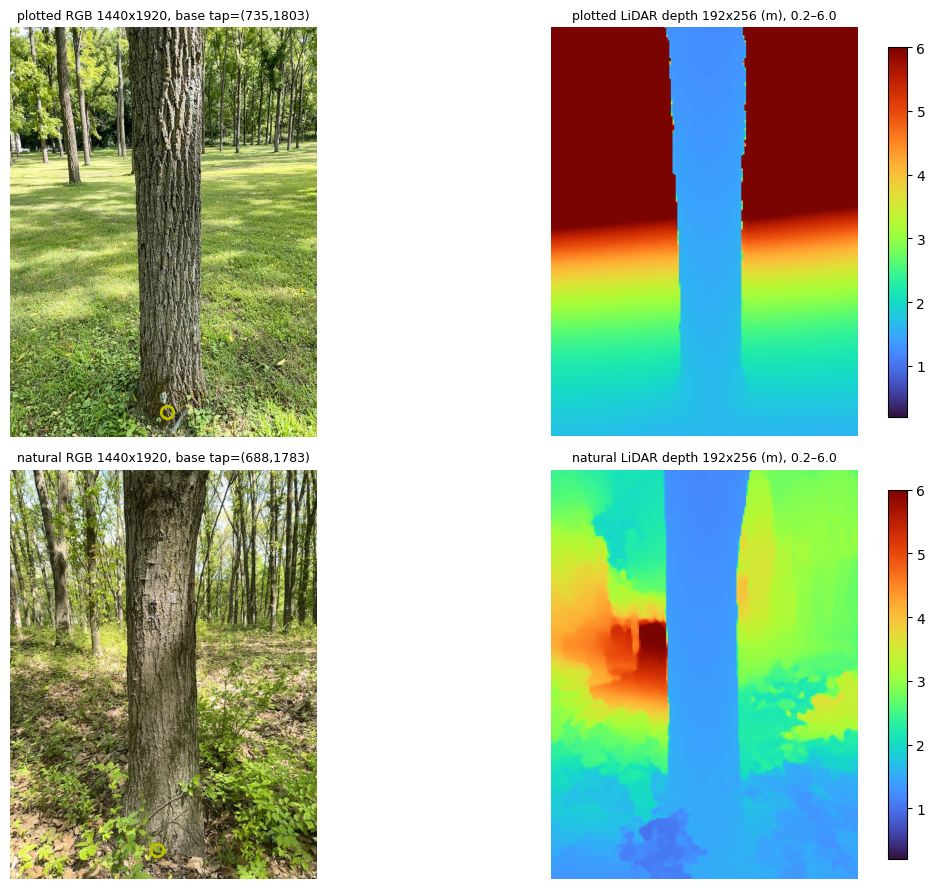

depth PNG metadata rows decode OK; valid-depth fraction: 0.9962565104166666


In [ ]:
import cv2, numpy as np, csv, matplotlib.pyplot as plt

def load_depth_png(path):
    img = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    assert img is not None and img.ndim == 2, f'unexpected combine PNG: {path}'
    assert img.dtype == np.uint16, img.dtype
    depth_m = img[4:].astype(np.float32) * (6.0 / (255.0 * 255.0))
    return img, depth_m

def base_point(name, dataset):
    with open(PROJECT / f'data/basePoints_{dataset}.csv', encoding='utf-8-sig') as f:
        for row in csv.DictReader(f):
            if row['uniqueName'] == name:
                return int(row['baseCol']), int(row['baseRow'])
    raise KeyError(name)

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for r, name in enumerate(['plotted', 'natural']):
    stem = samples[name][0]
    combined, depth_m = load_depth_png(PROJECT / f'data/rawdata/depth_{name}Field/combine-{stem}.png')
    bgr = cv2.imread(str(PROJECT / f'data/rawdata/rgb_{name}Field/rgb-{stem}.jpeg'), cv2.IMREAD_COLOR)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    bx, by = base_point(stem, name)
    axes[r, 0].imshow(rgb)
    axes[r, 0].plot([bx], [by], 'yo', ms=9, mfc='none', mew=2)
    axes[r, 0].set_title(f'{name} RGB {rgb.shape[1]}x{rgb.shape[0]}, base tap=({bx},{by})', fontsize=9)
    im = axes[r, 1].imshow(depth_m, cmap='turbo', vmin=0.2, vmax=6.0)
    axes[r, 1].set_title(f'{name} LiDAR depth {depth_m.shape[1]}x{depth_m.shape[0]} (m), 0.2–6.0', fontsize=9)
    plt.colorbar(im, ax=axes[r, 1], fraction=0.03)
for ax in axes.flat: ax.set_axis_off()
plt.tight_layout(); plt.show()
print('depth PNG metadata rows decode OK; valid-depth fraction:',
      float(((depth_m > 0.01) & (depth_m < 6.0)).mean()))

### 9. Run the depth-guided MobileSAMv2 DBH pipeline (both datasets)

Run the authors' compiled batch programs with `--save-masks` (their own overlay exporter: model mask + red tint + yellow breast-height dot). Each image goes through: depth edge extraction → cleaned edge rows → 3D growth direction → trunk rotation → depth-guided box prompt → MobileSAMv2 (ONNX, CPU) → mask-geometry DBH (cm) — compared in the CSV against the caliper reference (`dbhCaliper_cm`). Console lines below are the programs' own per-image status output.

** JA:** 著者のバッチプログラムを --save-masks 付きで両データセット実行します。深度エッジ→成長方向→回転→ボックスプロンプト→MobileSAMv2(ONNX/CPU)→幾何DBH(cm)、CSVにはキャリパー基準値も出力されます。

In [ ]:
import subprocess, time

def run_batch(binary, dataset, csv_name):
    out_csv = PROJECT / 'output/DBHResults/MobileSAMv2' / csv_name
    cmd = [f'/content/{binary}', str(PROJECT), str(out_csv), str(MAX_FILES),
           str(PROJECT / 'data'), '--save-masks']
    t0 = time.time()
    proc = subprocess.run(cmd, text=True, capture_output=True)
    print(proc.stdout)
    if proc.stderr: print('STDERR:', proc.stderr)
    print(f'[{binary}] exit={proc.returncode}, wall={time.time()-t0:.1f}s')
    assert proc.returncode == 0, f'{binary} failed with exit {proc.returncode}'
    return out_csv

csv_plot = run_batch('dbh_mobilesamv2_plot', 'plotted', 'results_MobileSAMv2_plot.csv')
csv_natural = run_batch('dbh_mobilesamv2_natural', 'natural', 'results_MobileSAMv2_natural.csv')

Project root: /content/dbh_project
Data directory: /content/dbh_project/data
Base points: /content/dbh_project/data/basePoints_plotted.csv
Labels: /content/dbh_project/data/labelsForPlottedField.csv
Mask export directory: /content/dbh_project/output/DBHResults/MobileSAMv2/masks/plot
1 3 720 1024 
Selected Mask Index: 1, Confidence Score: 0.922339
[1/2] 015F8CF6-A9A6-4C8F-B7F2-93904FB04611-240821162430: ok, diameter_m=0.312244, BH=(735,450)
1 3 720 1024 
Selected Mask Index: 1, Confidence Score: 0.957667
[2/2] 035A58BF-8751-422E-9AB5-49E6FF51D266-240821153726: ok, diameter_m=0.236103, BH=(773,533)
Saved 2 rows to /content/dbh_project/output/DBHResults/MobileSAMv2/results_MobileSAMv2_plot.csv
Succeeded: 2, failed: 0, base-point fallbacks: 0
Mask export: saved=2, already saved=0, failed=0

[dbh_mobilesamv2_plot] exit=0, wall=8.8s


Project root: /content/dbh_project
Data directory: /content/dbh_project/data
Base points: /content/dbh_project/data/basePoints_natural.csv
Labels: /content/dbh_project/data/labelsForNaturalField.csv
Mask export directory: /content/dbh_project/output/DBHResults/MobileSAMv2/masks/natural
1 3 720 1024 
Selected Mask Index: 1, Confidence Score: 0.991031
[1/2] 00CE6EF7-1B18-4126-BDE8-80855AC4656C-240502114743: ok, diameter_m=0.384099, BH=(713,233)
1 3 720 1024 
Selected Mask Index: 1, Confidence Score: 0.963923
[2/2] 01B59F0F-19A1-4514-987F-81C3E69CC69E-240502122621: ok, diameter_m=0.452079, BH=(750,255)
Saved 2 rows to /content/dbh_project/output/DBHResults/MobileSAMv2/results_MobileSAMv2_natural.csv
Succeeded: 2, skipped (no base point): 0, failed: 0, base-point fallbacks: 0
Mask export: saved=2, already saved=0, failed=0

STDERR: Warning: base-point CSV line 359 replaces an earlier entry for 1FFBD4EC-92E6-44C4-A134-A1E22CC4D504-240502113802: (658, 1552) -> (664, 1576)

[dbh_mobilesamv2_n

### 10. Results — estimated DBH vs caliper reference

Parse the authors' output CSVs (`dbhSAM_UV_cm` = geometric DBH from the MobileSAMv2 mask, cm; `dbhCaliper_cm` = caliper reference). Rows with `0` DBH are documented pipeline failures (kept visible, never silently dropped). Error is `estimated − caliper` in cm.

** JA:** 出力CSVを解析し、推定DBHとキャリパー基準値を比較します。0は失敗行としてそのまま表示します(除外しません)。

In [ ]:
import pandas as pd

frames = []
for label, path in [('plotted', csv_plot), ('natural', csv_natural)]:
    df = pd.read_csv(path)
    df['dataset'] = label
    frames.append(df)
results = pd.concat(frames, ignore_index=True)
ok = results['dbhSAM_UV_cm'] > 0
results['error_cm'] = results['dbhSAM_UV_cm'] - results['dbhCaliper_cm']
results['dbhSAM_UV_cm'] = results['dbhSAM_UV_cm'].round(2)
results['dbhCaliper_cm'] = results['dbhCaliper_cm'].round(1)
results['error_cm'] = results['error_cm'].round(2)
print(results[['dataset', 'uniqueName', 'dbhSAM_UV_cm', 'dbhCaliper_cm', 'error_cm']]
      .to_string(index=False))
print()
print(f'succeeded: {int(ok.sum())}/{len(results)} rows; '
      f'mean |error| on successes = {results.loc[ok, "error_cm"].abs().mean():.2f} cm' if ok.any() else 'no successful rows')
results.to_csv('/content/dbh_results_table.csv', index=False)
print('saved /content/dbh_results_table.csv')

dataset                                        uniqueName  dbhSAM_UV_cm  dbhCaliper_cm  error_cm
plotted 015F8CF6-A9A6-4C8F-B7F2-93904FB04611-240821162430         31.22           31.2      0.02
plotted 035A58BF-8751-422E-9AB5-49E6FF51D266-240821153726         23.61           23.3      0.31
natural 00CE6EF7-1B18-4126-BDE8-80855AC4656C-240502114743         38.41           36.3      2.12
natural 01B59F0F-19A1-4514-987F-81C3E69CC69E-240502122621         45.21           42.0      3.20

succeeded: 4/4 rows; mean |error| on successes = 1.41 cm
saved /content/dbh_results_table.csv


### 11. Overlay visualization (model output on the original input)

Display the authors' own exported overlays: the MobileSAMv2 trunk mask (red tint) and the estimated breast-height point (yellow dot, drawn only when localization succeeded) on the original RGB. These are **model predictions**, not reference annotations.

** JA:** 著者エクスポータが出力したオーバーレイ(モデルマスク=赤、推定胸高点=黄)を元画像上に表示します。これは**モデル予測**であり参照アノテーションではありません。

4 overlays: ['00CE6EF7-1B18-4126-BDE8-80855AC4656C-240502114743_overlay.png', '01B59F0F-19A1-4514-987F-81C3E69CC69E-240502122621_overlay.png', '015F8CF6-A9A6-4C8F-B7F2-93904FB04611-240821162430_overlay.png', '035A58BF-8751-422E-9AB5-49E6FF51D266-240821153726_overlay.png']


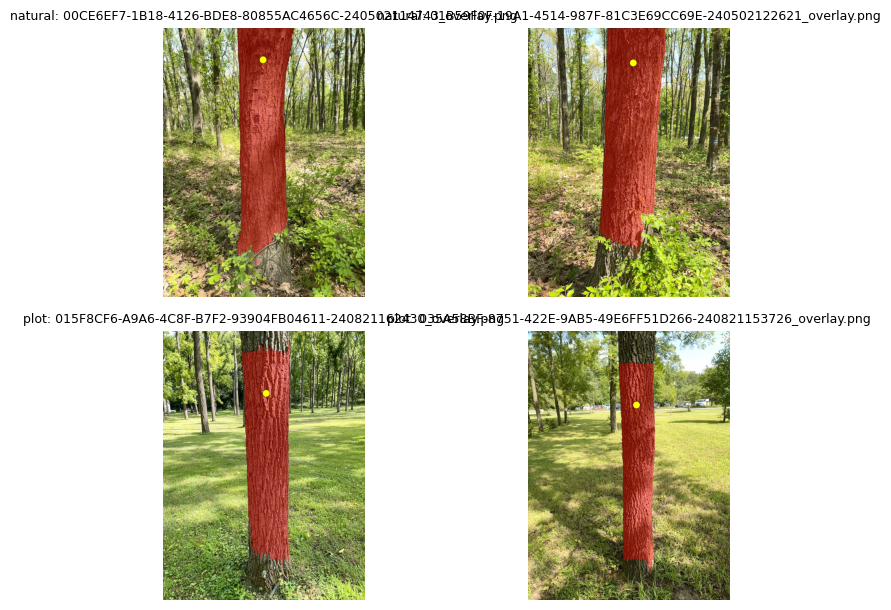

In [ ]:
import matplotlib.pyplot as plt, cv2, pathlib

overlay_root = PROJECT / 'output/DBHResults/MobileSAMv2/masks'
overlays = sorted(overlay_root.glob('*/overlays/*_overlay.png'))
assert overlays, 'no overlays exported'
print(len(overlays), 'overlays:', [p.name for p in overlays])
ncol = 2
nrow = (len(overlays) + 1) // 2
fig, axes = plt.subplots(nrow, ncol, figsize=(9, 6.2 * nrow / 2))
axes = np.atleast_2d(axes)
for i, p in enumerate(overlays):
    img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    ax = axes[i // ncol, i % ncol]
    ax.imshow(img)
    ax.set_title(f'{p.parent.parent.name}: {p.name}', fontsize=9)
    ax.set_axis_off()
for j in range(len(overlays), nrow * ncol): axes[j // ncol, j % ncol].set_axis_off()
plt.tight_layout(); plt.show()

### 12. Estimated vs caliper DBH (additional visualization created for this notebook)

A labeled scatter plot of the executed rows against the 1:1 identity line — an aid created for this notebook, **not** a reproduced paper figure (the paper's Figure 6/9 cover the full 202/285-tree datasets).

** JA:** 実行サンプルの推定値vsキャリパー値の散布図(本ノートブック用に追加作成した図であり、論文図の再現ではありません)。

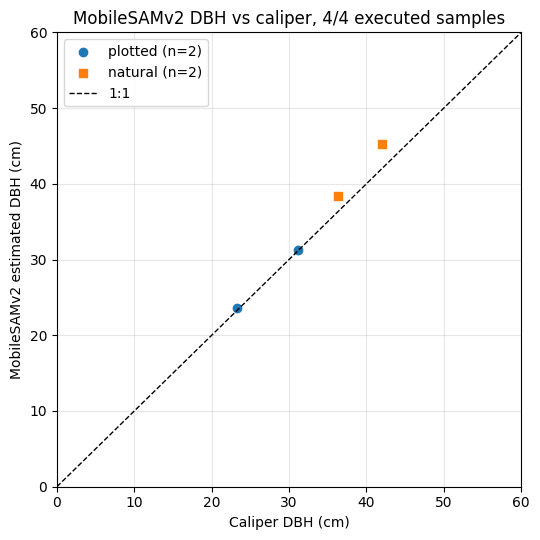

In [ ]:
import matplotlib.pyplot as plt

ok = results['dbhSAM_UV_cm'] > 0
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for label, marker in [('plotted', 'o'), ('natural', 's')]:
    sub = results[(results['dataset'] == label) & ok]
    ax.scatter(sub['dbhCaliper_cm'], sub['dbhSAM_UV_cm'], marker=marker, label=f'{label} (n={len(sub)})')
lim = [0, max(60, float(results.loc[ok, ['dbhCaliper_cm', 'dbhSAM_UV_cm']].max().max()) + 5)]
ax.plot(lim, lim, 'k--', lw=1, label='1:1')
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('Caliper DBH (cm)')
ax.set_ylabel('MobileSAMv2 estimated DBH (cm)')
ax.set_title(f'MobileSAMv2 DBH vs caliper, {int(ok.sum())}/{len(results)} executed samples')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Interpretation, limitations, and references

**What was executed (verified):** the authors' C++ MobileSAMv2 pipeline (verbatim algorithm sources, 4 documented Linux glue patches) on the first `MAX_FILES` sorted image pairs per dataset, with the authors' own ONNX exports and blob-hash-verified inputs; DBH (cm) compared with caliper labels; overlays from the authors' exporter.

**What this does not show:** the paper's dataset-level accuracy (RMSE 1.0 cm planted / 1.9 cm natural, R² 0.99/0.96 — 202/285 trees), the SAM3.1 framework, iPhone on-device timing (~0.89 s/image), and the authors' full visualization notebook. A handful of samples can disagree with the published statistics purely by sample choice.

**Known differences from the paper's environment:** Linux (Ubuntu, Colab) + OpenCV from apt + ONNX Runtime 1.24.1 CPU instead of Windows + OpenCV 4.11.0 + ORT 1.24.1; `wmain`→`main` and path-lookup adaptations documented in §6. Repository license: none recorded on GitHub (metadata checked 2026-11-14) — this notebook only executes the code and links it; paper text is CC BY 4.0 (author manuscript R3 via OpenAlex).

** JA:** 実行済み内容と限界を上記の通り明示します。少数サンプルのため論文のデータセット精度(RMSE等)は再現対象外です。

**References:** paper DOI 10.1088/1361-6501/aebfb9; code `yinzhiheng/AI-assisted-DBH-measurement-pipeline@672e7543123741ad11f2b41fdaeaec313427b555` (README §4, `codes/DBH/src/*`, `model/MobileSAMv2/onnx/*`); dataset `data/rawdata/*`, `data/basePoints_*.csv`, `data/labelsFor*Field.csv` in the same commit.